# v4_1 実験結果の確認

保存済みの実行設定、試行別・条件別集計、時系列、遺伝子型の推移を確認します。
上から順に実行してください。実験先は `experiment_name` で変更できます。
時系列と遺伝子型は各条件の最初の試行（run_id=0）の記録です。

In [25]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

project_dir = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                    if (p / "configs").is_dir() and (p / "data").is_dir()), None)
if project_dir is None:
    raise FileNotFoundError("project または notebooks ディレクトリから実行してください。")
experiment_name = "exp_v4_1_grid_search"
experiment_dir = project_dir / "data" / experiment_name
required_files = ["config_used.json", "raw_data.csv", "summary_data.csv",
                  "time_series_data.csv", "genotype_time_series_data.csv"]
missing = [name for name in required_files if not (experiment_dir / name).is_file()]
if missing:
    raise FileNotFoundError(f"{experiment_dir}: 不足ファイル {missing}")
config = json.loads((experiment_dir / "config_used.json").read_text(encoding="utf-8"))
raw_df = pd.read_csv(experiment_dir / "raw_data.csv")
summary_df = pd.read_csv(experiment_dir / "summary_data.csv")
time_series_df = pd.read_csv(experiment_dir / "time_series_data.csv")
# 先頭の0を含む9ビットの遺伝子型を文字列のまま保持します。
genotype_df = pd.read_csv(experiment_dir / "genotype_time_series_data.csv",
                          dtype={"genotype": "string"})
condition_columns = list(config["grid_parameters"])
print(f"読み込み先: {experiment_dir}")
display(config)
display(pd.DataFrame({"rows": {"raw": len(raw_df), "summary": len(summary_df),
    "time_series": len(time_series_df), "genotype": len(genotype_df)}}))
display(summary_df.sort_values(condition_columns).reset_index(drop=True))
display(raw_df.head())
display(time_series_df.head())
display(genotype_df.head())

読み込み先: /mnt/nfs/hera/nishimura/2703-nishimura-bachelor-thesis/project/data/exp_v4_1_grid_search


{'experiment_name': 'exp_v4_1_grid_search',
 'agent_class': 'AgentV4_1',
 'field_class': 'FieldV4_1',
 'simulation': {'total_steps': 200000,
  'eval_start_step': 100001,
  'num_runs': 10,
  'base_seed': 42,
  'workers': 15},
 'grid_parameters': {'initial_food_prob': [0.1],
  'step_food_prob': [0.003],
  'food_durability': [5],
  'death_threshold': [-120, -100, -80, -60, -40, -30, -20, -10, -5],
  'transfer_amount': [1]},
 'fixed_field_parameters': {'field_size': 10,
  'initial_agents': 20,
  'mutation_rate': 0.05,
  'energy_loss_per_step': 0.1,
  'reward_food': 1.0,
  'clone_threshold': 100.0}}

,rows
raw,90
summary,9
time_series,1800
genotype,7429


,initial_food_prob,step_food_prob,food_durability,death_threshold,transfer_amount,num_runs,avg_population,std_population,avg_within_run_std_population,avg_altruism_count,std_altruism_count,avg_within_run_std_altruism_count,avg_altruism_rate,std_altruism_rate,avg_death_age,std_death_age,avg_within_run_std_death_age
0,0.1,0.003,5,-120,1,10,14.825328,0.141379,0.894420,0.072617,0.222324,0.123249,0.004910,0.015035,67886.514739,12796.459193,55804.947599
1,0.1,0.003,5,-100,1,10,14.847663,0.131648,1.061379,0.121224,0.368985,0.155299,0.008211,0.024998,38873.941242,7102.486233,40383.737346
2,0.1,0.003,5,-80,1,10,14.777000,0.113763,1.048776,0.004924,0.003690,0.067427,0.000333,0.000249,33290.443741,8912.438239,38417.908993
3,0.1,0.003,5,-60,1,10,14.625373,0.133278,0.994476,0.024592,0.043327,0.125595,0.001684,0.002965,33999.320776,9028.146224,40909.278118
4,0.1,0.003,5,-40,1,10,14.434141,0.122615,1.061596,0.006576,0.005933,0.077016,0.000456,0.000412,22095.772873,4615.641614,29965.492945
5,0.1,0.003,5,-30,1,10,14.252795,0.105950,1.087718,0.108958,0.316686,0.190122,0.007673,0.022305,18639.585884,4779.396451,27938.749217
6,0.1,0.003,5,-20,1,10,13.909702,0.163165,1.043854,0.005871,0.002441,0.076568,0.000423,0.000178,12622.603149,2736.667344,20164.403247
7,0.1,0.003,5,-10,1,10,13.293228,0.402435,1.089266,0.005537,0.003497,0.071787,0.000423,0.000278,7759.770940,2210.361091,12641.571719
8,0.1,0.003,5,-5,1,10,12.592286,0.698066,1.304568,0.010190,0.019854,0.084562,0.000821,0.001597,6571.448286,2943.306534,13203.965903


,run_id,seed,avg_population,std_population,avg_altruism_count,std_altruism_count,avg_altruism_rate,avg_death_age,std_death_age,initial_food_prob,step_food_prob,food_durability,death_threshold,transfer_amount
0,0,42,13.50283,1.078037,0.00322,0.056830,0.000238,6762.411765,11566.043404,0.1,0.003,5,-10,1
1,1,43,13.58292,0.933752,0.00390,0.063284,0.000287,9348.818182,14655.086772,0.1,0.003,5,-10,1
2,2,44,13.17524,1.020089,0.00282,0.053217,0.000214,7207.585635,13260.479625,0.1,0.003,5,-10,1
3,3,45,12.67554,1.200542,0.01081,0.106458,0.000853,4859.848101,7912.697963,0.1,0.003,5,-10,1
4,4,46,13.70417,0.949402,0.00103,0.032077,0.000075,10553.140496,17282.021250,0.1,0.003,5,-10,1


,initial_food_prob,step_food_prob,food_durability,death_threshold,transfer_amount,run_id,seed,step,population,altruism_count,altruism_rate
0,0.1,0.003,5,-10,1,0,42,1000,8,1333,0.158220
1,0.1,0.003,5,-10,1,0,42,2000,11,428,0.042672
2,0.1,0.003,5,-10,1,0,42,3000,10,210,0.021199
3,0.1,0.003,5,-10,1,0,42,4000,12,178,0.015613
4,0.1,0.003,5,-10,1,0,42,5000,13,197,0.015524


,initial_food_prob,step_food_prob,food_durability,death_threshold,transfer_amount,run_id,seed,step,genotype,population
0,0.1,0.003,5,-10,1,0,42,1000,000000001011,2
1,0.1,0.003,5,-10,1,0,42,1000,011000110000,1
2,0.1,0.003,5,-10,1,0,42,1000,011001010000,1
3,0.1,0.003,5,-10,1,0,42,1000,011001110000,2
4,0.1,0.003,5,-10,1,0,42,1000,101011010110,1


## 条件ごとの集計比較

横軸は死亡閾値、線の分類は移譲量です。それ以外の条件は図を分けます。
エラーバーは試行平均の**試行間標本標準偏差**で、信頼区間ではありません。
標準偏差が欠損の場合も平均値を表示し、平均値の欠損はゼロに置き換えません。

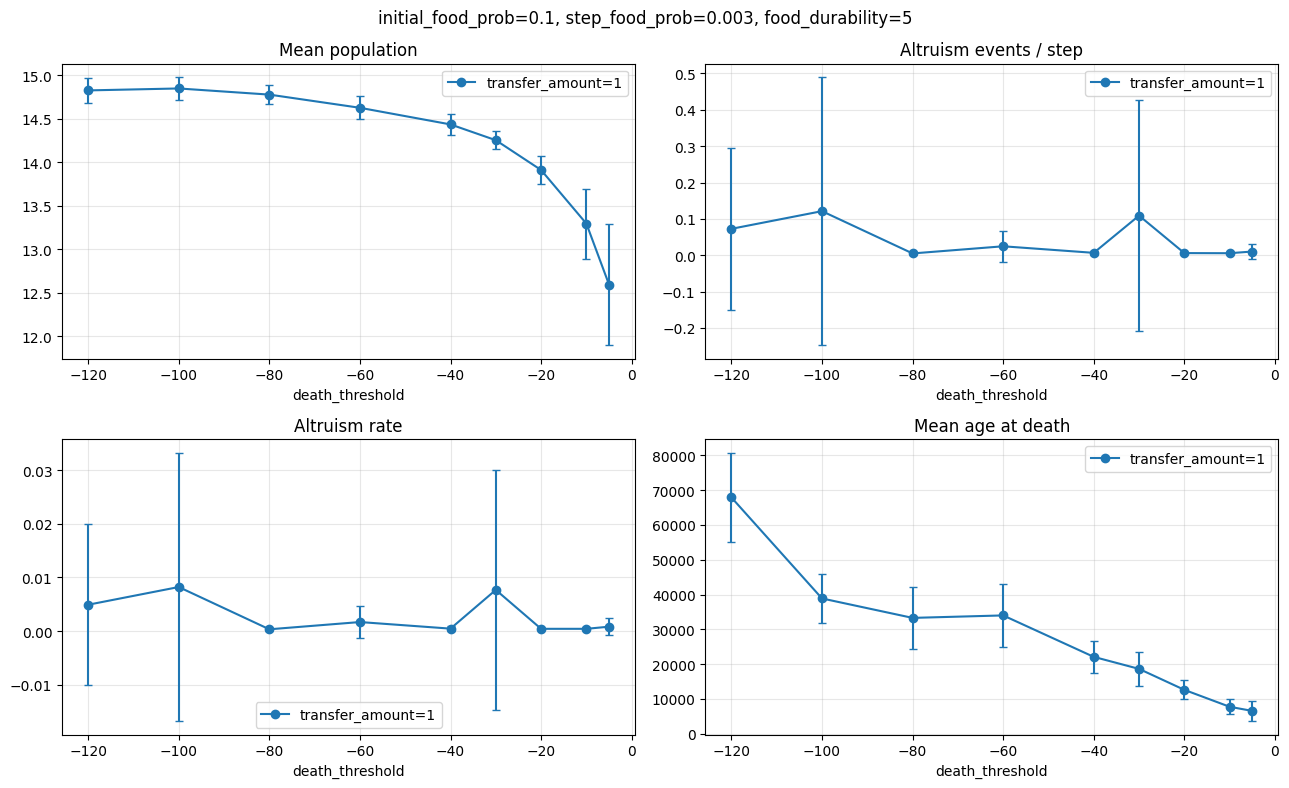

In [26]:
x_parameter = "death_threshold"
series_parameter = "transfer_amount"
# 例: {"step_food_prob": 0.003}。指定しなければ全条件を表示します。
comparison_filters = {}

def filter_rows(frame, filters):
    result = frame
    for column, value in filters.items():
        result = result.loc[result[column].eq(value)]
    return result

def grouped(frame, columns):
    if columns:
        yield from frame.groupby(columns, sort=True, dropna=False)
    else:
        yield (), frame

def condition_title(frame, columns):
    return ", ".join(f"{key}={frame[key].iloc[0]}" for key in columns)

metrics = [("avg_population", "std_population", "Mean population"),
           ("avg_altruism_count", "std_altruism_count", "Altruism events / step"),
           ("avg_altruism_rate", "std_altruism_rate", "Altruism rate"),
           ("avg_death_age", "std_death_age", "Mean age at death")]
comparison_df = filter_rows(summary_df, comparison_filters)
if comparison_df.empty:
    print("指定条件の集計データがありません。")
other_columns = [c for c in condition_columns if c not in (x_parameter, series_parameter)]
for _, group in grouped(comparison_df, other_columns):
    fig, axes = plt.subplots(2, 2, figsize=(13, 8))
    for value, line in grouped(group, [series_parameter]):
        line = line.sort_values(x_parameter)
        label = f"{series_parameter}={line[series_parameter].iloc[0]}"
        for axis, (mean, std, title) in zip(axes.flat, metrics):
            artist, = axis.plot(line[x_parameter], line[mean], "o-", label=label)
            valid = line[mean].notna() & line[std].notna()
            axis.errorbar(line.loc[valid, x_parameter], line.loc[valid, mean],
                          yerr=line.loc[valid, std], fmt="none", capsize=3,
                          color=artist.get_color())
            axis.set(title=title, xlabel=x_parameter)
            axis.grid(alpha=0.3)
            axis.legend()
    fig.suptitle(condition_title(group, other_columns))
    fig.tight_layout()
    plt.show()

## 個体数・利他行動の時系列

同じ死亡閾値について移譲量を比較します。他の条件や試行は混ぜません。
個体数は記録ステップ末の値です。利他行動数は前回記録後からの合計、
利他行動率はその合計を区間内のステップ末個体数の合計で割った値です。
ステップ1の区間は1ステップ、次のステップ3000の区間は2999ステップです。
絶滅後の利他行動率などの欠損値はそのまま表示します。

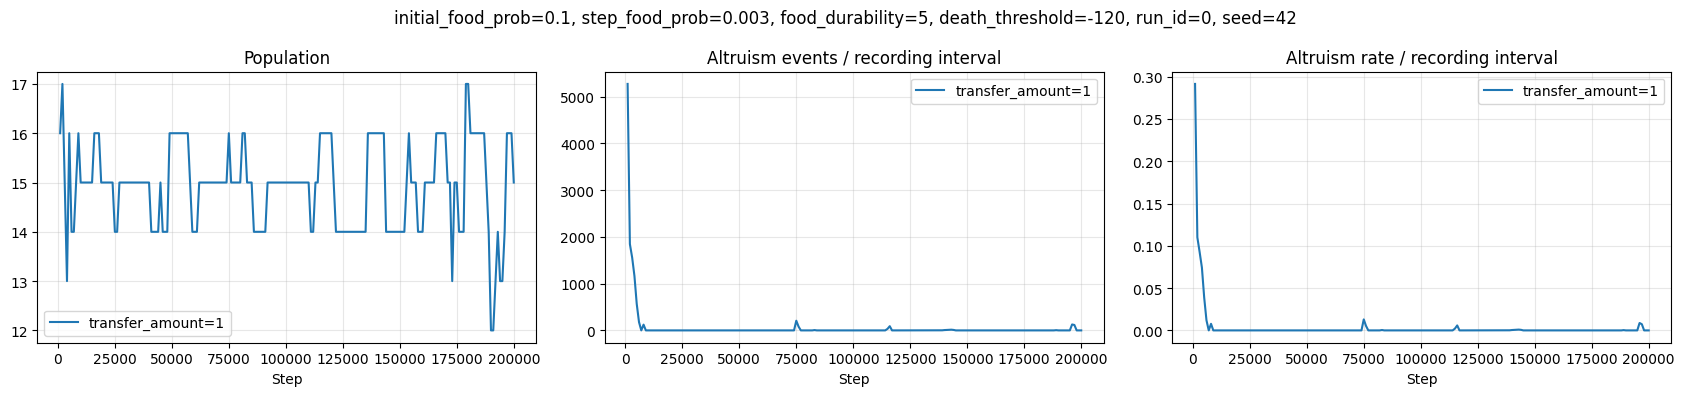

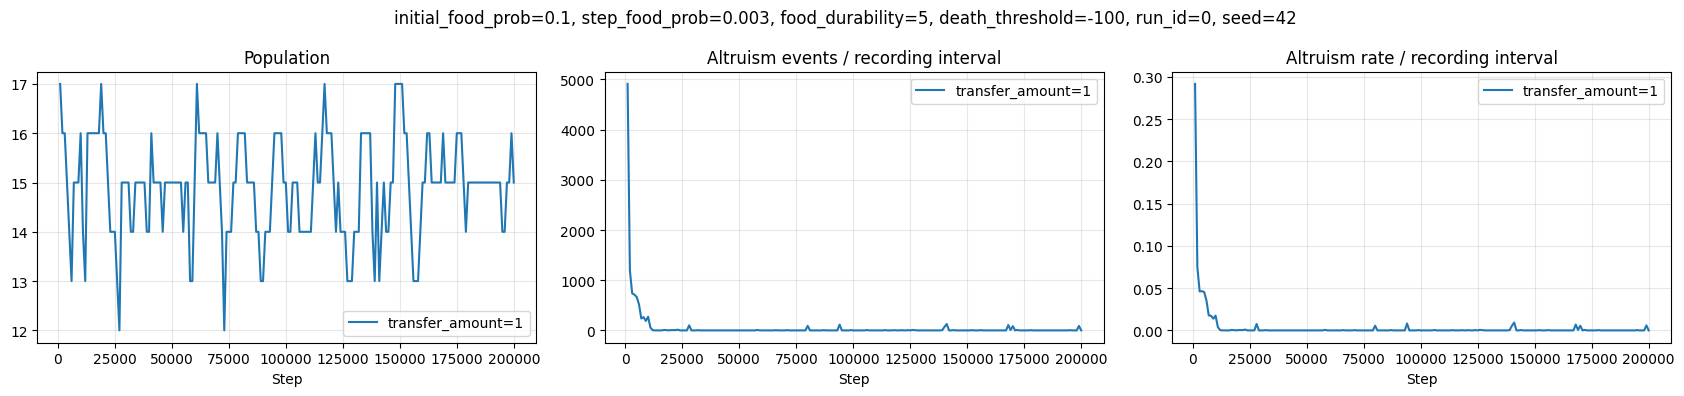

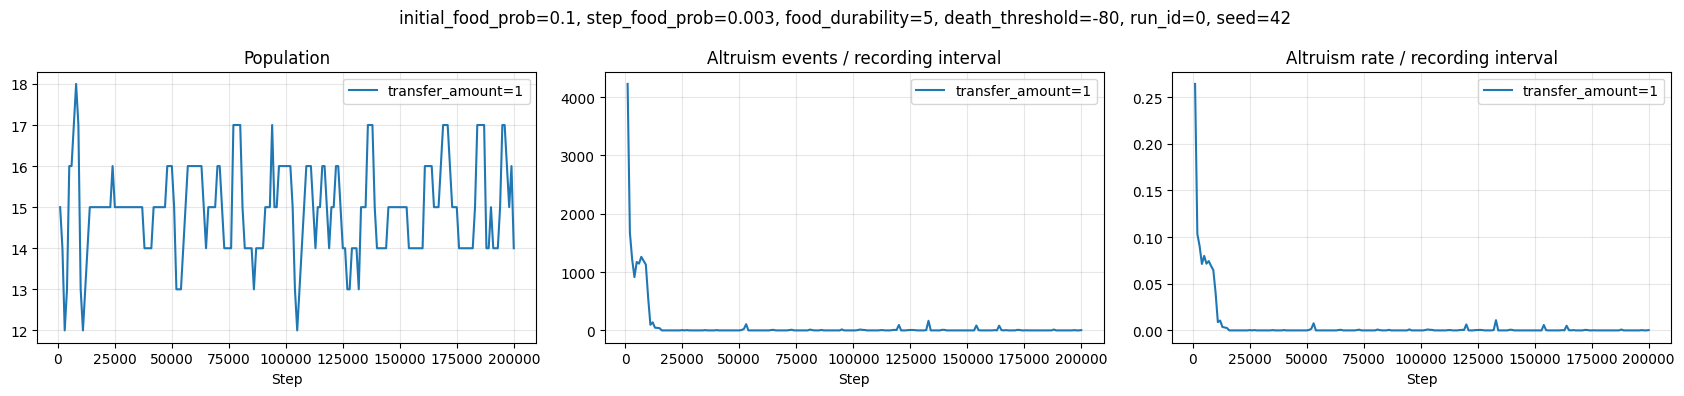

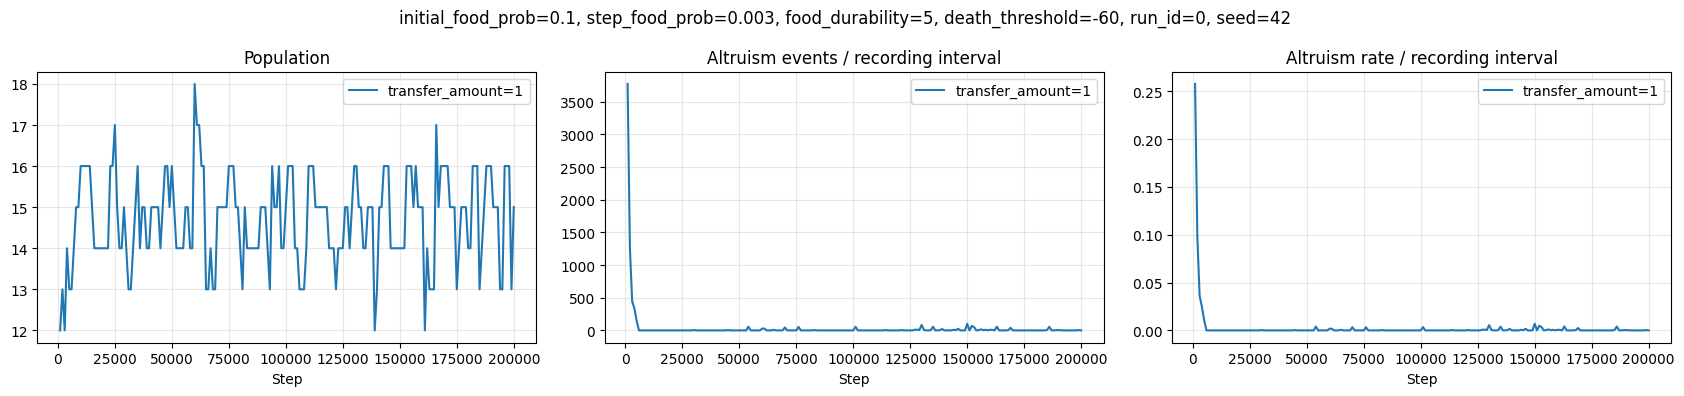

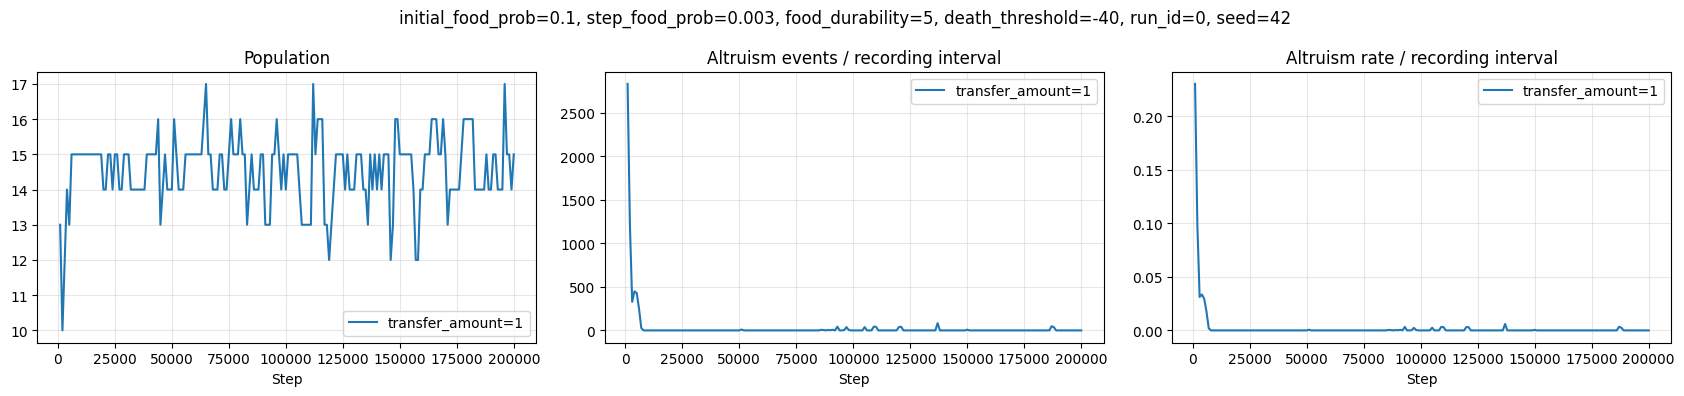

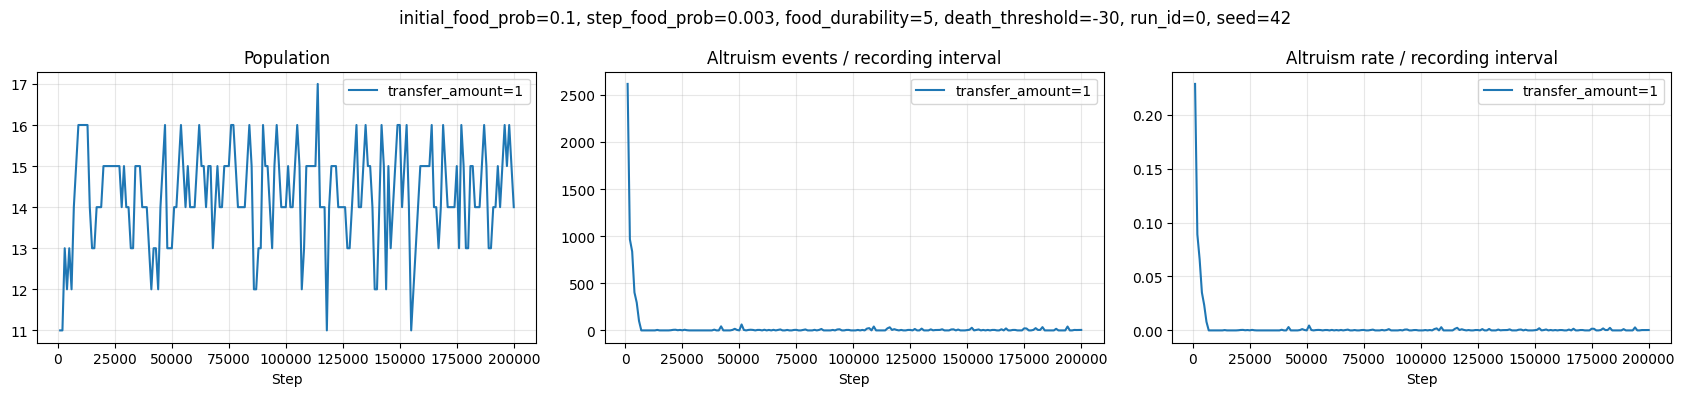

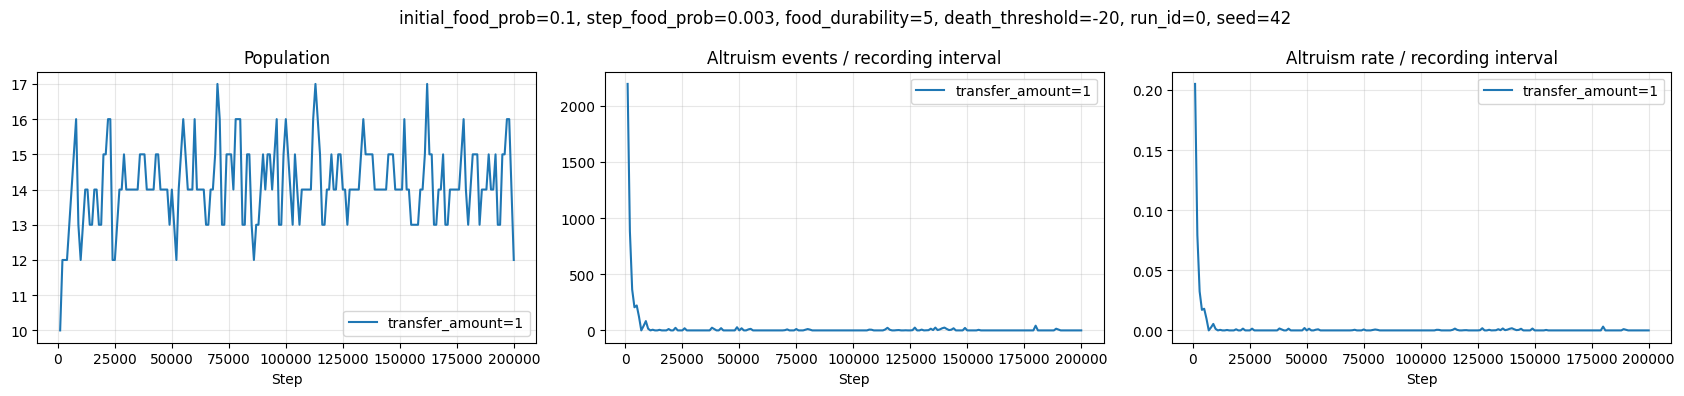

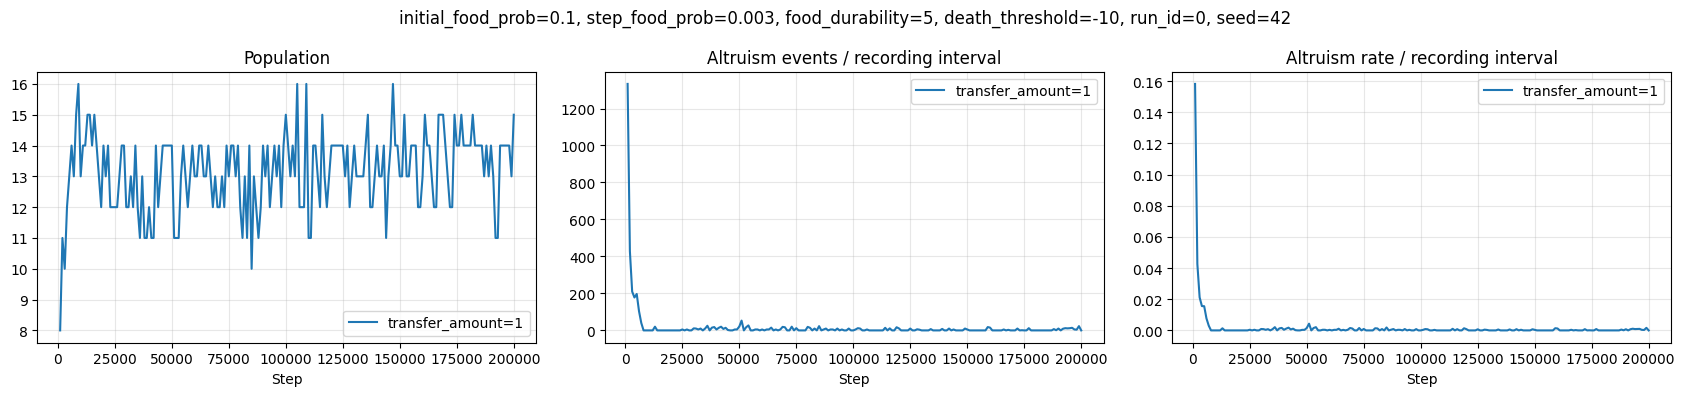

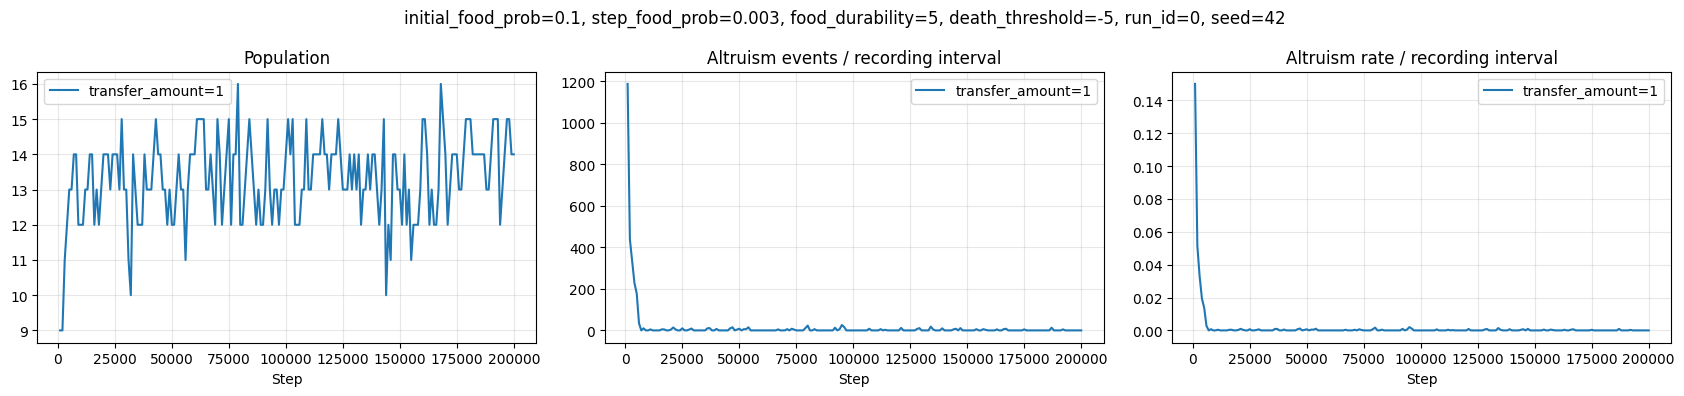

In [27]:
series_data = filter_rows(time_series_df, comparison_filters)
separate_columns = [c for c in condition_columns if c != series_parameter] + ["run_id", "seed"]
if series_data.empty:
    print("指定条件の時系列データがありません。")
for _, group in grouped(series_data, separate_columns):
    fig, axes = plt.subplots(1, 3, figsize=(17, 4), sharex=True)
    for _, line in grouped(group, [series_parameter]):
        line = line.sort_values("step")
        label = f"{series_parameter}={line[series_parameter].iloc[0]}"
        for axis, metric, title in zip(axes,
                ["population", "altruism_count", "altruism_rate"],
                ["Population", "Altruism events / recording interval", "Altruism rate / recording interval"]):
            axis.plot(line["step"], line[metric], label=label)
            axis.set(title=title, xlabel="Step")
            axis.grid(alpha=0.3)
            axis.legend()
    fig.suptitle(condition_title(group, separate_columns))
    fig.tight_layout()
    plt.show()

## 遺伝子型の推移

下の `genotype_filters` で表示する条件を変更できます。既定では最初の条件を表示します。
全期間の記録個体数合計が大きい上位8型と、それ以外の型を表示します。
頻度は各記録時点の総個体数に対する割合です。絶滅後は頻度が未定義のため空白になります。

In [30]:
genotype_keys = condition_columns + ["run_id", "seed"]
if time_series_df.empty:
    genotype_filters = {}
else:
    genotype_filters = time_series_df.sort_values(genotype_keys).iloc[0][genotype_keys].to_dict()
    genotype_filters["death_threshold"] = -10
# 例: genotype_filters["transfer_amount"] = 3
max_genotypes = 8
print("表示条件:", genotype_filters)

表示条件: {'initial_food_prob': 0.1, 'step_food_prob': 0.003, 'food_durability': 5.0, 'death_threshold': -10, 'transfer_amount': 1.0, 'run_id': 0.0, 'seed': 42.0}


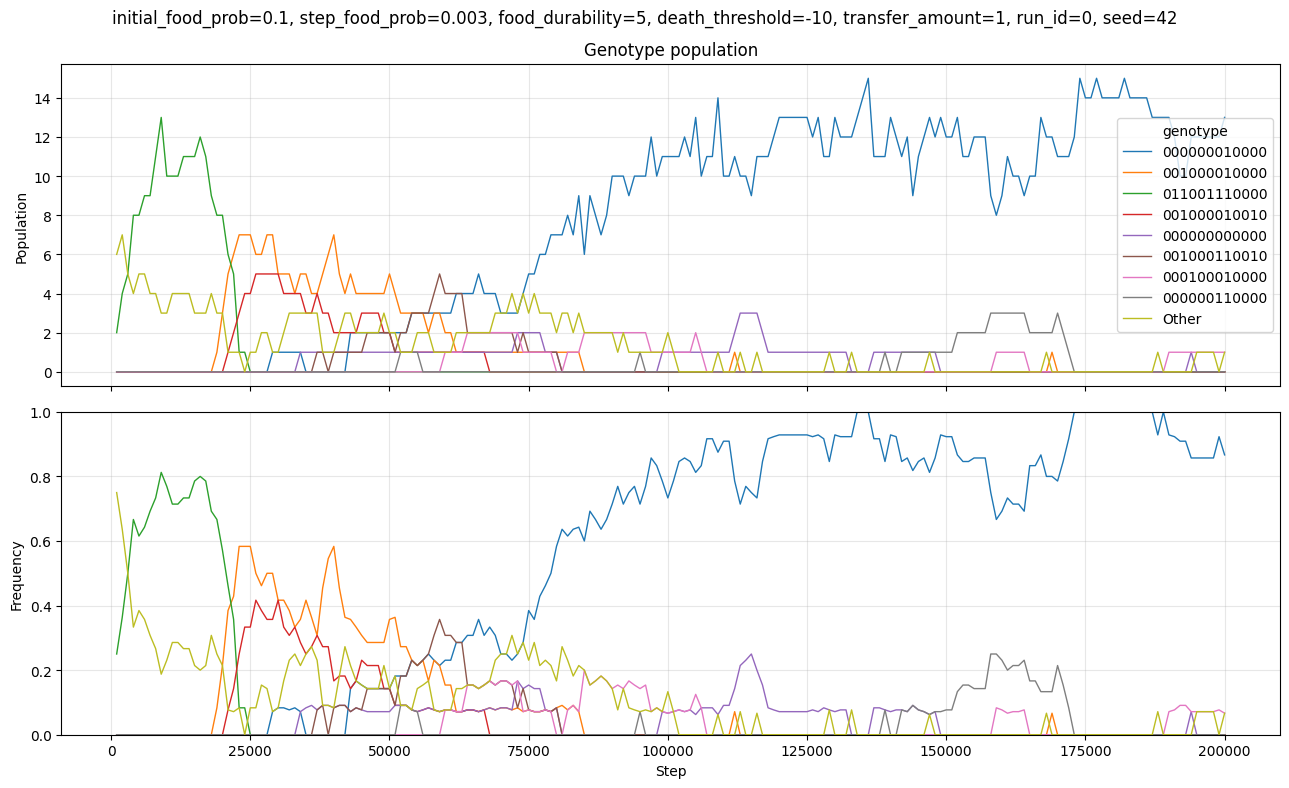

In [31]:
selected_series = filter_rows(time_series_df, genotype_filters)
selected_genotypes = filter_rows(genotype_df, genotype_filters)
for _, series in grouped(selected_series, genotype_keys):
    series = series.sort_values("step")
    filters = series.iloc[0][genotype_keys].to_dict()
    genes = filter_rows(selected_genotypes, filters)
    if genes.empty:
        print(f"遺伝子型の記録がありません: {filters}")
        continue
    counts = genes.pivot_table(index="step", columns="genotype", values="population",
                               aggfunc="sum", fill_value=0)
    counts = counts.reindex(series["step"], fill_value=0)
    top = counts.sum().sort_values(ascending=False).head(max_genotypes).index
    shown = counts.loc[:, top].copy()
    others = counts.drop(columns=top).sum(axis=1)
    if (others > 0).any():
        shown["Other"] = others
    totals = series.set_index("step")["population"]
    frequencies = shown.div(totals.where(totals > 0), axis=0)
    fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
    shown.plot(ax=axes[0], linewidth=1)
    frequencies.plot(ax=axes[1], linewidth=1, legend=False)
    axes[0].set(ylabel="Population", title="Genotype population")
    axes[1].set(xlabel="Step", ylabel="Frequency", ylim=(0, 1))
    for axis in axes:
        axis.grid(alpha=0.3)
    fig.suptitle(condition_title(series, genotype_keys))
    fig.tight_layout()
    plt.show()